# RoV vs MLBB — inspect one reproducible pipeline run

Notebook นี้อ่าน **snapshot ของรอบที่ระบุ** ไม่ได้ดึงข้อมูลสดเมื่อกด Run All
ค่าเริ่มต้นใช้ sample ที่ติดป้ายข้อมูลจำลอง รัน `rov-mlbb run --config config/sample.json` ก่อน
ถ้าจะดูข้อมูลจริง ให้ตั้ง `ROV_RUN_DIR` เป็นโฟลเดอร์ run จริงก่อนเริ่ม kernel
หรือแก้ `RUN_DIR` ใน cell ถัดไปแล้ว Restart + Run All

คำถามสำหรับผู้วิเคราะห์คอนเทนต์เกม: การค้นหา การเผยแพร่วิดีโอ และรีวิวที่เก็บได้
ต่างกันอย่างไรระหว่างเกมและเดือน ภายใต้ขอบเขตแหล่งข้อมูลที่กำหนด?
ยังไม่ใช้ตัวชี้วัดเหล่านี้แทนจำนวนผู้เล่นหรือหลักฐานการย้ายเกม

In [1]:
import io
import os
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from rov_mlbb.report import load_run, select_metrics, plot_metrics

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'config/sample.json').exists())
explicit_run = os.environ.get('ROV_RUN_DIR')
if explicit_run:
    RUN_DIR = Path(explicit_run).resolve()
else:
    pointer = json.loads((ROOT / 'artifacts/sample/latest_complete.json').read_text(encoding='utf-8'))
    RUN_DIR = ROOT / 'artifacts/sample/runs' / pointer['run_id']
manifest, metrics = load_run(RUN_DIR)
label = ('SYNTHETIC DEMO — NOT RESEARCH FINDINGS' if manifest['data_kind'] == 'sample'
         else 'REAL COLLECTED DATA — CHECK COVERAGE BEFORE INTERPRETATION')
display(Markdown(f"## {label}\nRun: `{manifest['run_id']}` | Status: **{manifest['status']}**"))
print('Snapshot:', RUN_DIR)
print('Python:', sys.executable)
print('Processed:', manifest['finished_at'])

## REAL COLLECTED DATA — CHECK COVERAGE BEFORE INTERPRETATION
Run: `fd1a7d895cb3477ea72591e4199e5e38` | Status: **partial**

Snapshot: D:\Projects\Dataen-Rov_vs_Mlbb\artifacts\real\runs\fd1a7d895cb3477ea72591e4199e5e38
Python: D:\Projects\Dataen-Rov_vs_Mlbb\tmp\verify-venv\Scripts\python.exe
Processed: 2026-11-02T15:29:35.896947+00:00


## ขอบเขตและวันเก็บข้อมูล

เวลาประมวลผลไม่ใช่เวลาเก็บข้อมูล ยอดวิวเป็นยอดสะสม ณ เวลาเก็บของวิดีโอที่เผยแพร่ในเดือนนั้น
`complete` หมายถึงครบภายในกรอบตัวอย่างที่ประกาศเท่านั้น
`partial` = ข้อมูลบางส่วน, `filtered` = มีแถวถูกคัดออก, `missing` = ไม่มีข้อมูล

In [2]:
provenance = []
for source, quality in manifest['sources'].items():
    packet_path = RUN_DIR / 'raw' / f'{source}.json'
    packet = json.loads(packet_path.read_text(encoding='utf-8')) if packet_path.exists() else {}
    provenance.append({
        'source': source,
        'collected_at': quality.get('collected_at'),
        'collection_time_status': quality.get('collection_time_status', 'missing'),
        'collected_no_later_than': quality.get('provenance', {}).get('collected_no_later_than'),
        'exported_at': quality.get('provenance', {}).get('exported_at'),
        'selection': packet.get('context', {}).get('selection', quality.get('reason')),
        'coverage': json.dumps(quality.get('coverage', {}), ensure_ascii=False),
        'raw_sha256': quality.get('raw_sha256'),
    })
display(pd.DataFrame(provenance))

,source,collected_at,collection_time_status,collected_no_later_than,exported_at,selection,coverage,raw_sha256
0,playstore,NaN,unknown,2026-03-17T09:42:59.316150+00:00,2026-11-02T15:21:48.600290+00:00,"Original notebook: country th, request lang_so...","{""mlbb"": {""end"": ""2026-02-04"", ""note"": ""All do...",448aa06959a88b6b49015dc5fa9c8d62e010b9474241bb...
1,trends,2026-11-02T15:26:51.407431+00:00,known,NaN,NaN,One Google Trends request comparing both terms...,"{""mlbb"": {""end"": ""2026-03-14"", ""note"": ""Google...",667f7c3c12468e1b4db065cb4a1d3e49afd555fe447e4c...
2,youtube,NaN,unknown,2026-03-16T07:51:01.117452+00:00,2026-11-02T15:21:52.012858+00:00,Original notebook selected channels and case-s...,"{""mlbb"": {""end"": ""2026-03-10"", ""note"": ""All do...",fd97e5e0d668e539bb982a72f1cc4f49b390bfdb2ca268...


## ตัวกรองและกราฟ

ใช้ controls เมื่อเปิดใน Jupyter/VS Code ที่รองรับ widgets หรือแก้พารามิเตอร์ด้านล่างแล้วรัน cell
กราฟและตารางใช้ข้อมูลจาก run เดียวกัน ช่องว่างคงเป็นค่าที่ไม่ทราบ ไม่เติมศูนย์

**REAL COLLECTED DATA — CHECK COVERAGE BEFORE INTERPRETATION** | `fd1a7d895cb3477ea72591e4199e5e38`

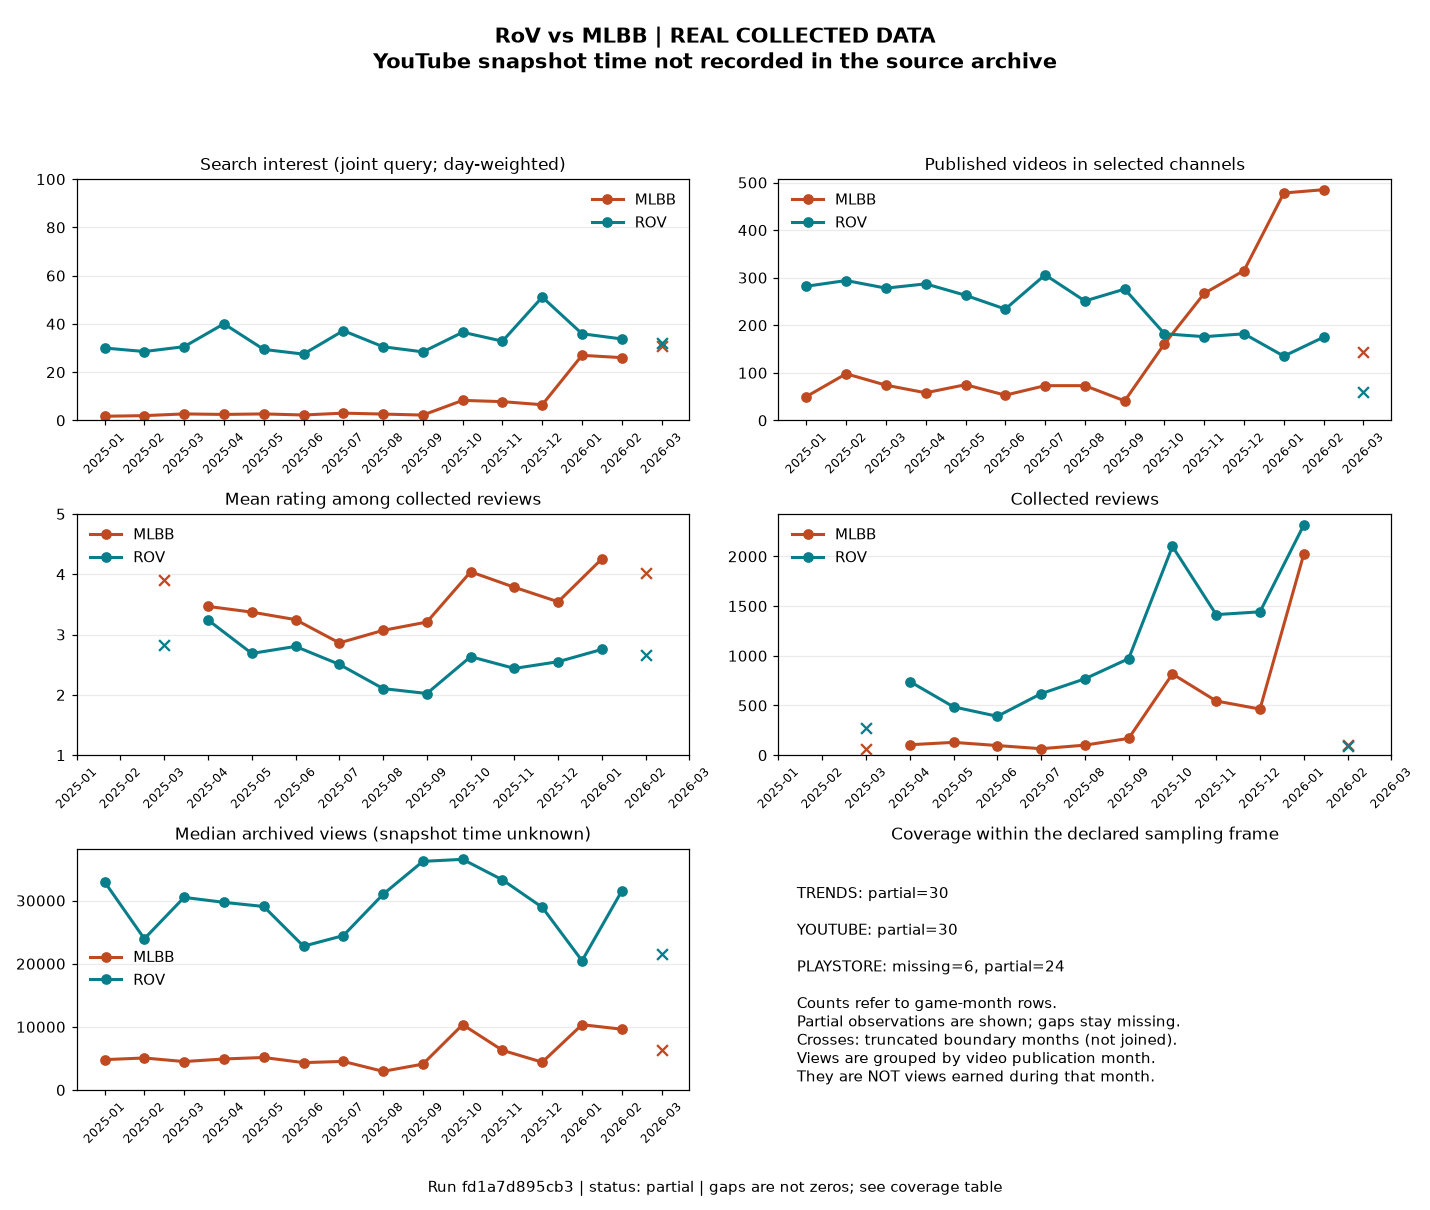

,month,game,search_interest,published_video_count,median_views_at_collection,sampled_channel_count,review_count,mean_review_rating
1,2025-01,mlbb,1.709677,50,4804.0,4,NaN,NaN
0,2025-01,rov,30.000000,282,32971.5,21,NaN,NaN
3,2025-02,mlbb,1.964286,98,5069.0,6,NaN,NaN
2,2025-02,rov,28.535714,294,23955.5,19,NaN,NaN
5,2025-03,mlbb,2.677419,74,4500.5,6,59.0,3.898305
4,2025-03,rov,30.548387,278,30504.0,18,274.0,2.832117
7,2025-04,mlbb,2.466667,58,4911.5,6,105.0,3.466667
6,2025-04,rov,40.033333,287,29717.0,19,741.0,3.241565
9,2025-05,mlbb,2.677419,75,5147.0,9,129.0,3.372093
8,2025-05,rov,29.419355,263,29062.0,17,486.0,2.687243


,month,game,trends_coverage,youtube_coverage,playstore_coverage,trends_collected_at,youtube_collected_at,playstore_collected_at
1,2025-01,mlbb,partial,partial,missing,2026-11-02T15:26:51.407431+00:00,None,None
0,2025-01,rov,partial,partial,missing,2026-11-02T15:26:51.407431+00:00,None,None
3,2025-02,mlbb,partial,partial,missing,2026-11-02T15:26:51.407431+00:00,None,None
2,2025-02,rov,partial,partial,missing,2026-11-02T15:26:51.407431+00:00,None,None
5,2025-03,mlbb,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None
4,2025-03,rov,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None
7,2025-04,mlbb,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None
6,2025-04,rov,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None
9,2025-05,mlbb,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None
8,2025-05,rov,partial,partial,partial,2026-11-02T15:26:51.407431+00:00,None,None


In [3]:
GAME = 'all'  # all, rov, mlbb
START_MONTH = metrics['month'].min()
END_MONTH = metrics['month'].max()

def show_selection(game=GAME, start=START_MONTH, end=END_MONTH):
    selected = select_metrics(metrics, game, start, end)
    display(Markdown(f'**{label}** | `{manifest["run_id"]}`'))
    fig = plot_metrics(manifest, selected)
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))
    display(selected[['month', 'game', 'search_interest', 'published_video_count',
                      'median_views_at_collection', 'sampled_channel_count',
                      'review_count', 'mean_review_rating']])
    display(selected[['month', 'game', 'trends_coverage', 'youtube_coverage',
                      'playstore_coverage', 'trends_collected_at',
                      'youtube_collected_at', 'playstore_collected_at']])
    return selected

selected = show_selection()

In [4]:
import ipywidgets as widgets
months = sorted(metrics['month'].unique())
game_control = widgets.Dropdown(options=['all', 'rov', 'mlbb'], value=GAME, description='Game')
start_control = widgets.Dropdown(options=months, value=START_MONTH, description='From')
end_control = widgets.Dropdown(options=months, value=END_MONTH, description='To')
output = widgets.Output()
button = widgets.Button(description='Apply filters')
def refresh(_):
    with output:
        output.clear_output(wait=True)
        try:
            show_selection(game_control.value, start_control.value, end_control.value)
        except ValueError as error:
            print(str(error))
button.on_click(refresh)
display(widgets.VBox([widgets.HBox([game_control, start_control, end_control]), button, output]))

## สุขภาพ pipeline และการตรวจย้อนกลับ

ตารางนี้อธิบายสิ่งที่เกิดขึ้นระหว่างประมวลผล แยกจากตัวชี้วัดเกมด้านบน
ตรวจจำนวน input = accepted + exact duplicates + rejected สำหรับแต่ละแหล่งที่มีข้อมูล

In [5]:
quality_rows = []
for source, row in manifest['sources'].items():
    if 'input_rows' in row:
        assert row['input_rows'] == row['accepted_rows'] + row['duplicate_rows'] + row['rejected_rows']
    quality_rows.append({'source': source, **{key: row.get(key) for key in
        ['input_rows', 'accepted_rows', 'duplicate_rows', 'rejected_rows', 'reasons', 'status']}})
assert not metrics.duplicated(['month', 'game']).any()
assert metrics['run_id'].eq(manifest['run_id']).all()
display(pd.DataFrame(quality_rows))
print('Traceability and game-month uniqueness checks passed.')
print('CSV:', RUN_DIR / 'summary/monthly_game_metrics.csv')
print('Manifest:', RUN_DIR / 'manifest.json')

,source,input_rows,accepted_rows,duplicate_rows,rejected_rows,reasons,status
0,playstore,16288,16288,0,0,{},None
1,trends,126,124,0,2,{'partial_trend_interval': 2},None
2,youtube,5826,5826,0,0,{},None


Traceability and game-month uniqueness checks passed.
CSV: D:\Projects\Dataen-Rov_vs_Mlbb\artifacts\real\runs\fd1a7d895cb3477ea72591e4199e5e38\summary\monthly_game_metrics.csv
Manifest: D:\Projects\Dataen-Rov_vs_Mlbb\artifacts\real\runs\fd1a7d895cb3477ea72591e4199e5e38\manifest.json


## การอ่านผลและข้อจำกัด

- Sample ใช้ทดสอบวิธีคำนวณและระบบเท่านั้น ห้ามใช้เป็นข้อค้นพบด้านเกม
- Trends เป็นดัชนีภายใน joint query เดียว เปลี่ยนคำค้นหรือช่วงเวลาจะเปลี่ยนฐานเปรียบเทียบ
- กรณีข้อมูลรายสัปดาห์ การเฉลี่ยรายเดือนถ่วงด้วยวันทับซ้อนเป็นค่าประมาณ
- YouTube ครอบคลุมช่องและชื่อคลิปตามกฎที่เลือก ยอดวิวสะสมสัมพันธ์กับอายุวิดีโอ
- คะแนนรีวิวต้องอ่านคู่กับจำนวนและ coverage; ภาษา request ไม่ยืนยันสัญชาติผู้เขียน
- ข้อมูลเพียงหนึ่งเดือนไม่พออธิบายแนวโน้มหลายเดือน และข้อมูลที่ขาดไม่ยืนยันว่าไม่มีความสนใจ
- ข้อค้นพบชุดข้อมูลย้อนหลังอยู่ใน `docs/historical_findings.md`; รอบทดลองเชื่อมต่ออยู่ใน `docs/pilot_findings.md`
- วันเก็บยอดวิวเดิมที่ไม่ทราบคงเป็น null; เวลา export และเวลาที่ข้อมูลอยู่ใน Firestore ไม่ใช่วันเก็บต้นทาง

ก่อนส่งอาจารย์ ให้ยืนยันช่วงศึกษาและเกณฑ์ส่งงาน เติมข้อมูลจริงที่ขาด
และอัปเดตรายงานให้ชี้ไปยัง run ที่ใช้สรุปจริง